# Data Analysis: Data Acquisition — APIs, Web Scraping and File Formats

> **Who is this for:** a beginner who can write basic Python and use pandas, and who now wants to *get* data from the outside world: files from colleagues, REST APIs, and web pages. Also useful for university students (BS/MS Data Science "Data Wrangling" or "Data Engineering" courses) and for interview prep.
>
> **What you will learn:**
> - the main **data sources** (files, databases, APIs, web pages, streams) and the **legal and ethical rules** (licences, robots.txt, terms of service, personal data)
> - **file formats**: CSV traps (encoding, delimiters, quoting), JSON / JSON Lines and `pd.json_normalize`, XML, Excel, Parquet and Feather, with a size and speed comparison
> - a robust **REST API client**: authentication headers, pagination, retries with exponential backoff, rate limits (HTTP 429) and response caching (ETag / HTTP 304)
> - **web scraping** with BeautifulSoup: CSS selectors, `pd.read_html` for tables, messy markup, polite crawling with `urllib.robotparser`
> - **cleaning scraped text** with regular expressions, and parsing **dates and time zones** correctly (including daylight-saving traps)
> - **incremental loading** with watermarks and idempotent upserts into SQLite, plus **data provenance** (source, time, hash for every pull)
> - an industry mini-case: a **daily price-tracker dataset** built from a paginated API and HTML pages
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), [pandas](03_pandas.ipynb), [data preprocessing](01_data_preprocessing.ipynb). Helpful but optional: [SQL fundamentals](../13_Databases/01_sql/01_sql_fundamentals.ipynb), [computer networks for AI apps](../23_Software_Engineering/07_computer_networks_for_ai_apps.ipynb).
>
> **Time needed:** about 2 to 3 hours.
>
> **Runs on:** CPU, no API key. **No internet is used:** every "website" and "API" in this notebook is a tiny local server started by the notebook itself on `127.0.0.1` and stopped again in a `try/finally` block.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

Before you can analyse data, you have to **collect** it, and data lives in many places: a spreadsheet a colleague emails you, a company database, an "API" (a website made for programs instead of people), or an ordinary web page. **Data acquisition** is the skill of getting that data into Python reliably, legally and repeatably. A file can look simple but hide traps, such as strange letters (encoding) or commas inside a value. An API gives you data in small "pages" and gets angry (it says "slow down!") if you ask too fast. A web page mixes the data with layout, so you must pick out the parts you need. Finally, a professional pipeline remembers **what it already downloaded**, so tomorrow it only fetches what is new, and it writes down **where every number came from**.

**Everyday examples:**
- Calling an API page by page is like reading a long restaurant menu that the waiter brings **one page at a time**: you ask for page 1, then page 2, until he says "that was the last page".
- Polite scraping is like visiting a library: you read the **house rules at the door** (`robots.txt`), you do not run between the shelves, and you do not take books from the "staff only" room.
- A watermark is like a **bookmark**: next time you open the book, you start where you stopped instead of re-reading from page 1.

**Tiny example:** a shop API has 24 products and returns 10 per page. You need 3 requests: page 1 (products 1–10), page 2 (11–20), page 3 (21–24, and "no next page"). Tomorrow only 4 prices changed, so with a watermark you download **4 rows instead of 24**.

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| REST API + pagination | ask a server for data in numbered pages | weather, stock-price and social-media APIs; collecting LLM training or evaluation data |
| Web scraping | read data out of a web page's HTML | price comparison sites, job boards, building text datasets |
| Incremental load + provenance | fetch only what is new, and record where it came from | every data warehouse and feature store; dataset cards for ML models |

### How this notebook is different from its neighbours

| Notebook | Focus |
|---|---|
| [01_data_preprocessing](01_data_preprocessing.ipynb) | cleaning data that is **already** in a DataFrame |
| [10_duckdb](10_duckdb.ipynb) | querying files (Parquet, CSV) with SQL |
| [13_Databases/06_data_engineering](../13_Databases/06_data_engineering/01_data_engineering.ipynb) | ETL pipelines, orchestration, data quality |
| **This notebook** | getting data **in**: formats, APIs, scraping, incremental and traceable loading |

## 0. Setup

Everything we write goes into a temporary folder that is deleted at the end. `requests` is the classic HTTP client for Python, `bs4` (BeautifulSoup) parses HTML, and `pyarrow` reads and writes Parquet/Feather.

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import io, os, re, csv, json, gzip, time, hashlib, sqlite3, tempfile, threading, unicodedata, contextlib, socket
import shutil, urllib.parse, urllib.robotparser
import xml.etree.ElementTree as ET
from datetime import datetime, timezone, timedelta
from zoneinfo import ZoneInfo
from http.server import ThreadingHTTPServer, BaseHTTPRequestHandler

import requests                       # HTTP client
from bs4 import BeautifulSoup         # HTML parser
import pyarrow                        # Parquet / Feather engine for pandas

WORK = tempfile.mkdtemp(prefix="acq_")       # all files of this notebook live here
print("requests", requests.__version__, "| pyarrow", pyarrow.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3
requests 2.34.2 | pyarrow 24.0.0


---
## 1. The data-source landscape, and the rules of the game

> 💬 **In plain English:** know where data can come from, and what you are allowed to do with it.

| Source | Typical examples | How you read it | Main pitfalls |
|---|---|---|---|
| **Files** | CSV/Excel exports, JSON dumps, Parquet in a data lake | `pd.read_csv`, `pd.read_json`, `pd.read_parquet` | encoding, types, versions ("final_v3.xlsx") |
| **Databases** | PostgreSQL, MySQL, SQLite, a warehouse (BigQuery, Snowflake) | SQL via a driver, `pd.read_sql` | load on production systems, permissions |
| **APIs** | REST/JSON, GraphQL, gRPC | an HTTP client (`requests`, `httpx`) | auth, pagination, rate limits, schema changes |
| **Web pages** | product pages, tables on Wikipedia | download HTML + parse (`bs4`, `pd.read_html`) | layout changes, legality, JavaScript-rendered pages |
| **Streams** | Kafka topics, webhooks, IoT sensors | a consumer that runs continuously | ordering, duplicates, late events |

**Rule of thumb:** prefer the most **structured, official** source. An official API or a data export is more stable and more clearly allowed than scraping the same numbers from HTML.

### Legal and ethical checklist (not legal advice)
1. **Licence.** Data is not free just because it is visible. Open data often has a licence (e.g. CC BY 4.0 requires attribution; ODbL requires share-alike for derived databases). Copy the licence into your dataset documentation.
2. **Terms of service (ToS).** Many sites forbid automated access or reuse in their ToS. Breaking ToS can get your IP blocked or lead to legal action, even if the data is public.
3. **`robots.txt`.** A text file at `https://site/robots.txt` that says which paths automated clients may visit and how fast. It is a convention, not a lock, but respecting it is the baseline of good behaviour (and of most companies' policies).
4. **Personal data.** Names, emails, faces, IDs fall under privacy laws such as the EU **GDPR** or California's **CCPA/CPRA**: you need a lawful basis, data minimisation, and security. "It was public" is not a lawful basis by itself.
5. **Load.** Do not hammer servers: add delays, cache, and identify yourself with an honest `User-Agent`.

> ⚠️ **Common mistake:** treating "I can download it" as "I may use it". For ML training data in particular, record the source and licence of every dataset; regulations such as the EU AI Act ask providers of general-purpose AI models for a summary of their training content.

---
## 2. File formats

> 💬 **In plain English:** every file format has its own traps; tell pandas exactly what the file looks like.

### 2.1 CSV: simple format, many traps

A **CSV (comma-separated values)** file is plain text: one record per line, fields separated by a **delimiter**. There is a standard (**RFC 4180**), but real files break it all the time. The four traps you will meet first:

| Trap | Example | Fix |
|---|---|---|
| **Encoding** | `Café` saved by old Excel in Windows-1252, read as UTF-8 → error or `CafÃ©` | `encoding="cp1252"` (or detect), save as UTF-8 |
| **Delimiter and decimal** | European export: `1.234,50;Berlin` | `sep=";", decimal=",", thousands="."` |
| **Quoting** | a field containing a comma or a newline must be in quotes: `"Lahore, PK"` | use a real CSV parser, never `line.split(",")` |
| **Types** | ZIP/ID `00123` becomes the number `123`; `03/04/2026` is March or April? | `dtype={"id": str}`, explicit date `format=` |

Let us create a broken file of each kind and read it correctly.

In [2]:
# Trap 1: ENCODING. Write bytes the way an old Windows program would (cp1252), then read them back.
text = "city,price\nCafé Lumière,4.50\nMünchen,3.20\n"
p_enc = os.path.join(WORK, "legacy.csv")
with open(p_enc, "wb") as f:
    f.write(text.encode("cp1252"))          # é = byte 0xE9 in cp1252, but that byte is invalid as UTF-8 here

try:
    pd.read_csv(p_enc)                       # pandas assumes UTF-8 by default
except UnicodeDecodeError as e:
    print("UTF-8 read fails:", type(e).__name__, "-", str(e)[:70], "...")

print(pd.read_csv(p_enc, encoding="cp1252"))  # correct: tell pandas the real encoding
print("Raw bytes of 'é' in this file:", "é".encode("cp1252"), "| in UTF-8 it would be:", "é".encode("utf-8"))

UTF-8 read fails: UnicodeDecodeError - 'utf-8' codec can't decode byte 0xe9 in position 14: invalid continuat ...
           city  price
0  Café Lumière    4.5
1       München    3.2
Raw bytes of 'é' in this file: b'\xe9' | in UTF-8 it would be: b'\xc3\xa9'


In [3]:
# Trap 2 + 3 + 4: European delimiter/decimal, quoted fields with commas and newlines, leading zeros.
euro = (
    'id;customer;address;amount;order_date\n'
    '00123;"Ahmad, Sara";"12 Mall Road\nLahore";1.234,50;03/04/2026\n'
    '00456;Lee;"5 Main St, Apt 2";99,90;15/04/2026\n'
)
p_euro = os.path.join(WORK, "euro.csv")
with open(p_euro, "w", encoding="utf-8", newline="") as f:
    f.write(euro)

# The naive way: split lines by "\n" and fields by ";" -> the quoted newline breaks the record in two
naive = [line.split(";") for line in euro.strip().split("\n")]
print("Naive split gives", len(naive) - 1, "data 'rows' (wrong, there are 2):", naive[1])

# The csv module can even GUESS the dialect (delimiter, quote char) from a sample
dialect = csv.Sniffer().sniff(euro[:200])
print("Sniffer detected delimiter:", repr(dialect.delimiter))

df_euro = pd.read_csv(
    p_euro, sep=";", decimal=",", thousands=".",     # European number format
    dtype={"id": str},                                 # keep leading zeros: IDs are labels, not numbers
)
df_euro["order_date"] = pd.to_datetime(df_euro["order_date"], format="%d/%m/%Y")  # explicit: day first
print(df_euro)
print(df_euro.dtypes.to_dict())
assert df_euro.loc[0, "amount"] == 1234.50 and df_euro.loc[0, "id"] == "00123"
assert df_euro.loc[0, "order_date"].month == 4        # 3 April, not 4 March

Naive split gives 3 data 'rows' (wrong, there are 2): ['00123', '"Ahmad, Sara"', '"12 Mall Road']
Sniffer detected delimiter: ';'
      id     customer               address  amount order_date
0  00123  Ahmad, Sara  12 Mall Road\nLahore  1234.5 2026-04-03
1  00456          Lee      5 Main St, Apt 2    99.9 2026-04-15
{'id': dtype('O'), 'customer': dtype('O'), 'address': dtype('O'), 'amount': dtype('float64'), 'order_date': dtype('<M8[ns]')}


**What just happened?** The naive split produced three "rows" because one address contains a newline inside quotes; the real parser understood the quotes and produced two. Declaring `sep`, `decimal`, `thousands`, `dtype` and the date `format` turned text into correct numbers, labels and dates. **Always write these assumptions explicitly**: the default guesses of any library are made for US-style CSV files.

### 2.2 JSON, JSON Lines and nested data

**JSON** (JavaScript Object Notation) stores nested objects (`{}`) and lists (`[]`). It is the language of web APIs. **JSON Lines** (`.jsonl`, also called NDJSON) puts **one JSON object per line**: you can append to it and read it line by line, which is why logs and LLM fine-tuning datasets use it.

Nested JSON does not fit a flat table directly. `pd.json_normalize` **flattens** it: nested objects become dotted column names, and a nested list can become its own table with `record_path`, keeping parent fields via `meta`.

In [4]:
orders = [
    {"order_id": 1, "customer": {"id": "C7", "country": "PK"},
     "items": [{"sku": "A1", "qty": 2, "price": 3.5}, {"sku": "B2", "qty": 1, "price": 10.0}]},
    {"order_id": 2, "customer": {"id": "C9", "country": "DE"},
     "items": [{"sku": "A1", "qty": 5, "price": 3.5}]},
]

# JSON Lines: one object per line -> easy to append and stream
p_jsonl = os.path.join(WORK, "orders.jsonl")
with open(p_jsonl, "w", encoding="utf-8") as f:
    for o in orders:
        f.write(json.dumps(o) + "\n")
print(open(p_jsonl).read().splitlines()[0][:80], "...")

# Level 1: one row per order; nested dict -> dotted columns; list stays a Python list
print(pd.json_normalize(orders).drop(columns="items"))

# Level 2: one row per ITEM, carrying parent fields along (meta)
items = pd.json_normalize(orders, record_path="items",
                          meta=["order_id", ["customer", "id"], ["customer", "country"]])
items["line_total"] = items["qty"] * items["price"]
print(items)
assert len(items) == 3 and items["line_total"].sum() == 2*3.5 + 10 + 5*3.5
assert pd.read_json(p_jsonl, lines=True).shape[0] == 2     # pandas reads JSONL directly

{"order_id": 1, "customer": {"id": "C7", "country": "PK"}, "items": [{"sku": "A1 ...
   order_id customer.id customer.country
0         1          C7               PK
1         2          C9               DE
  sku  qty  price order_id customer.id customer.country  line_total
0  A1    2    3.5        1          C7               PK         7.0
1  B2    1   10.0        1          C7               PK        10.0
2  A1    5    3.5        2          C9               DE        17.5


### 2.3 XML

**XML** is the older, more verbose cousin of JSON: elements with opening/closing tags, attributes, and often **namespaces** (a prefix that says which vocabulary a tag belongs to). You still meet it in RSS feeds, banking (ISO 20022), office documents, sitemaps and government data. Python's built-in `xml.etree.ElementTree` is enough for most files.

> ⚠️ **Security note:** never parse XML from untrusted sources with a parser that expands external entities (the "XXE" attack). The standard library's ElementTree does not fetch external entities, but for hostile input the `defusedxml` package is the recommended safe wrapper.

In [5]:
xml_text = """<?xml version="1.0" encoding="UTF-8"?>
<catalog xmlns:p="https://example.org/pricing">
  <product id="A1" category="snacks">
    <name>Masala Chips</name>
    <p:price currency="PKR">250</p:price>
  </product>
  <product id="B2" category="drinks">
    <name>Mango Juice</name>
    <p:price currency="PKR">180</p:price>
  </product>
</catalog>"""

root = ET.fromstring(xml_text)
ns = {"p": "https://example.org/pricing"}                 # map the prefix to its namespace URI
rows = []
for prod in root.findall("product"):                       # every <product> child of <catalog>
    price = prod.find("p:price", ns)                       # namespaced tag needs the ns map
    rows.append({"id": prod.get("id"),                     # attribute
                 "category": prod.get("category"),
                 "name": prod.findtext("name"),            # text of a child element
                 "price": float(price.text),
                 "currency": price.get("currency")})
df_xml = pd.DataFrame(rows)
print(df_xml)
print("Same result with pandas (lxml engine):")
print(pd.read_xml(io.StringIO(xml_text), xpath="//product"))

   id category          name  price currency
0  A1   snacks  Masala Chips  250.0      PKR
1  B2   drinks   Mango Juice  180.0      PKR
Same result with pandas (lxml engine):
   id category          name  price
0  A1   snacks  Masala Chips    250
1  B2   drinks   Mango Juice    180


### 2.4 Excel, Parquet and Feather

- **Excel (`.xlsx`)** is a zipped bundle of XML files. pandas reads it with the `openpyxl` engine. Traps: several sheets, merged header cells, numbers stored as text, dates stored as serial numbers (days since 1899-12-30).
- **Parquet** is a **columnar**, compressed, typed binary format. Columnar means values of one column are stored together, so reading 2 of 50 columns reads roughly 2/50 of the data, and similar values compress very well. It keeps types (dates stay dates) and is the standard of data lakes, Spark, DuckDB and Hugging Face datasets.
- **Feather** (Arrow IPC) is a very fast binary format for passing DataFrames between Python and R or between processes; less compression than Parquet, great for temporary files.

In [6]:
small = pd.DataFrame({"sku": ["A1", "B2"], "price": [3.5, 10.0], "added": pd.to_datetime(["2026-01-05", "2026-02-10"])})
try:
    import openpyxl                                         # optional: only needed for Excel
    p_xlsx = os.path.join(WORK, "prices.xlsx")
    small.to_excel(p_xlsx, sheet_name="prices", index=False)
    print(pd.read_excel(p_xlsx, sheet_name="prices"))
except ImportError:
    print("openpyxl is not installed: skipping the Excel demo (pip install openpyxl to try it).")

# Excel stores dates as a serial number of days since 1899-12-30. If a file gives you raw serials:
serials = pd.Series([46027, 46063])
print("Excel serials -> dates:", pd.to_datetime(serials, unit="D", origin="1899-12-30").dt.date.tolist())

openpyxl is not installed: skipping the Excel demo (pip install openpyxl to try it).
Excel serials -> dates: [datetime.date(2026, 1, 5), datetime.date(2026, 2, 10)]


Now a **size and speed comparison** on a medium table (100,000 rows, 6 columns: IDs, categories, floats, timestamps). We write and read the same DataFrame in each format and also check that the types survive the round trip.

In [7]:
rng = np.random.default_rng(0)
n = 100_000
big = pd.DataFrame({
    "order_id": np.arange(n),
    "store": rng.choice(["Lahore", "Karachi", "Islamabad", "Berlin", "Austin"], n),
    "category": pd.Categorical(rng.choice(["snacks", "drinks", "dairy", "bakery"], n)),
    "price": rng.gamma(2.0, 3.0, n).round(2),
    "qty": rng.integers(1, 10, n),
    "ts": pd.Timestamp("2026-01-01") + pd.to_timedelta(rng.integers(0, 300*86400, n), unit="s"),
})

def bench(name, write, read, path):
    t0 = time.perf_counter(); write(path); t_w = time.perf_counter() - t0
    t0 = time.perf_counter(); back = read(path); t_r = time.perf_counter() - t0
    types_ok = (str(back["ts"].dtype).startswith("datetime64") and back["price"].dtype == "float64")
    return {"format": name, "size_MB": os.path.getsize(path) / 1e6, "write_s": t_w, "read_s": t_r,
            "keeps_datetime_type": types_ok}

results = [
    bench("CSV", lambda p: big.to_csv(p, index=False), pd.read_csv, os.path.join(WORK, "b.csv")),
    bench("CSV + gzip", lambda p: big.to_csv(p, index=False, compression="gzip"), pd.read_csv, os.path.join(WORK, "b.csv.gz")),
    bench("JSON Lines", lambda p: big.to_json(p, orient="records", lines=True, date_format="iso"),
          lambda p: pd.read_json(p, lines=True), os.path.join(WORK, "b.jsonl")),
    bench("Parquet (snappy)", lambda p: big.to_parquet(p, index=False), pd.read_parquet, os.path.join(WORK, "b.parquet")),
    bench("Feather", lambda p: big.to_feather(p), pd.read_feather, os.path.join(WORK, "b.feather")),
]
fmt = pd.DataFrame(results).set_index("format")
fmt["size_vs_csv"] = (fmt["size_MB"] / fmt.loc["CSV", "size_MB"]).round(2)
print(fmt.round(3))

# Columnar advantage: read only 2 of 6 columns from Parquet
t0 = time.perf_counter(); two = pd.read_parquet(os.path.join(WORK, "b.parquet"), columns=["store", "price"])
print(f"\nParquet, 2 columns only: {time.perf_counter() - t0:.3f} s, shape {two.shape}")

                  size_MB  write_s  read_s  keeps_datetime_type  size_vs_csv
format                                                                      
CSV                 4.750    0.570   0.133                False         1.00
CSV + gzip          1.249    1.264   0.154                False         0.26
JSON Lines         10.850    0.288   0.471                False         2.28
Parquet (snappy)    1.882    0.256   0.032                 True         0.40
Feather             2.580    0.030   0.013                 True         0.54

Parquet, 2 columns only: 0.015 s, shape (100000, 2)


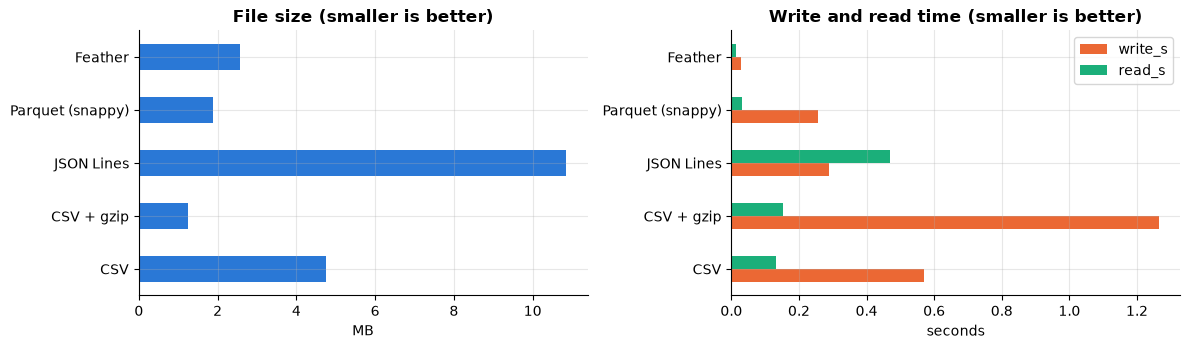

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
fmt["size_MB"].plot.barh(ax=axes[0], color=PALETTE[0])
axes[0].set(title="File size (smaller is better)", xlabel="MB", ylabel="")
fmt[["write_s", "read_s"]].plot.barh(ax=axes[1], color=[PALETTE[1], PALETTE[2]])
axes[1].set(title="Write and read time (smaller is better)", xlabel="seconds", ylabel="")
plt.tight_layout(); plt.show()

**What just happened?** Read the table and chart. Plain CSV and JSON Lines are big (JSON Lines repeats every column name in every row) and slow to read, and the text formats **lose types**: timestamps come back as strings unless you parse them again. gzip makes CSV small, but costs extra time to write and read and still loses the types. Parquet is well under half the CSV size here and Feather about half (column `size_vs_csv`), both read many times faster, and both keep `datetime64` and categorical columns. Reading only 2 columns from Parquet is faster still. Exact timings depend on the machine (and on how busy it is), but the ranking is typical.

| Format | Human-readable | Typed | Compressed | Append-friendly | Best for |
|---|---|---|---|---|---|
| CSV | yes | no | optional (gzip) | yes | exchange with humans/Excel |
| JSON / JSONL | yes | partly | no | JSONL yes | APIs, logs, nested records, LLM datasets |
| XML | yes | with schema | no | no | legacy, documents, feeds |
| Excel | in Excel | partly | zip | no | business users |
| Parquet | no | yes | yes (columnar) | by adding files | analytics, data lakes, ML datasets |
| Feather | no | yes | light | no | fast temporary interchange |

> 🎓 **Exam / interview tip:** "Why is Parquet faster for analytics?" → columnar layout (read only needed columns, column-wise compression and encoding such as dictionary/run-length), stored statistics (min/max per row group) that let engines **skip** chunks, and no text parsing.

---
## 3. A local practice server (our "internet")

> 💬 **In plain English:** we build a fake shop website on our own computer so we can practise safely.

To practise APIs and scraping **without the internet and without bothering a real website**, we build a tiny web server with Python's standard library. It pretends to be a shop:

| Path | What it returns | Special behaviour (for practice) |
|---|---|---|
| `/robots.txt` | crawl rules | disallows `/private/`, asks for 1 s between requests |
| `/api/products?page=&per_page=&updated_since=` | JSON page of products | needs header `Authorization: Bearer demo-token`; **every 7th API call returns 429** ("too many requests"); the **first** call for page 3 fails with **503**; supports **ETag / 304** |
| `/shop/page1.html`, `/shop/page2.html` | a competitor's HTML product list | messy markup, prices in different formats |
| `/shop/stores.html` | an HTML table | for `pd.read_html` |
| `/private/admin.html` | a page we must **not** crawl | listed in robots.txt |

The shop changes prices every simulated **day** (`SHOP.day`), so we can practise daily, incremental loads. The server runs in a background thread and is always shut down in a `try/finally` block by the `running_server()` context manager.

In [9]:
class ShopState:
    """All data and counters of the fake shop. Prices depend on (product, day) through a seeded RNG."""
    N_PRODUCTS = 24
    BRANDS = [("Kolson", "PK"), ("Shan", "PK"), ("Haribo", "DE"), ("Lay's", "US")]
    NAMES = ["Chips", "Biscuits", "Gummies", "Noodles", "Tea", "Juice", "Spice Mix", "Crackers"]

    def __init__(self):
        self.day = 0                    # simulated day number (0 = 2026-10-01)
        self.api_calls = 0              # used for the deterministic "every 7th call" rate limit
        self.failed_once = set()        # pages that already had their one transient 503
        self.log = []                   # (path, status) of every request, so we can inspect traffic

    def date(self, day=None):
        return datetime(2026, 10, 1, tzinfo=timezone.utc) + timedelta(days=self.day if day is None else day)

    def product(self, pid):
        brand, country = self.BRANDS[pid % len(self.BRANDS)]
        base = 100 + 15 * (pid % 9) + 5 * pid                     # base price in PKR
        # A product's price changes on a few days only: find its last change day <= today
        last_change = max([d for d in range(self.day + 1) if d == 0 or (pid * 7 + d * 3) % 5 == 0])
        r = np.random.default_rng(1000 * pid + last_change)
        price = round(base * (1 + 0.15 * (r.random() - 0.5)), 0)
        return {"id": pid, "name": f"{brand} {self.NAMES[pid % len(self.NAMES)]} {pid:02d}",
                "brand": {"name": brand, "country": country},
                "price": {"amount": price, "currency": "PKR"},
                "tags": ["snack"] if pid % 2 else ["snack", "family-pack"],
                "updated_at": (self.date(last_change) + timedelta(hours=6)).isoformat()}

    def competitor_price(self, pid):
        """The competitor sells the same products, usually a bit cheaper, sometimes much cheaper."""
        own = self.product(pid)["price"]["amount"]
        r = np.random.default_rng(50_000 + 100 * pid + self.day)
        return round(own * (0.97 - 0.12 * (r.random() < 0.15) + 0.04 * r.random()), 0)


SHOP = ShopState()
API_TOKEN = "demo-token"            # a fake token; real tokens come from env vars / a secrets manager, never from code

In [10]:
def fmt_price(pid, amount):
    """The competitor's website is inconsistent: three different price formats (for the regex section)."""
    style = pid % 3
    if style == 0:
        return f"Rs. {amount:,.0f}"
    if style == 1:
        return f"PKR&nbsp;{amount:.2f}"
    return f"{amount:,.0f}/- only"


def render_shop_page(page, per_page=12):
    ids = range((page - 1) * per_page, min(page * per_page, SHOP.N_PRODUCTS))
    cards = []
    for pid in ids:
        p = SHOP.product(pid)
        badge = '<span class="badge sale">SALE!</span>' if pid % 4 == 0 else ""
        # deliberately messy: inconsistent whitespace, a missing </li>, an HTML entity, attributes in odd order
        cards.append(f"""
          <li class="product-card" data-sku="SKU-{pid:04d}">
             <h3 class="title">  {p['name'].replace("'", "&#39;")}  </h3>{badge}
             <p class="price" >{fmt_price(pid, SHOP.competitor_price(pid))}</p>
             <a href="/shop/item/{pid}.html">details</a>
        """ + ("</li>" if pid % 5 else ""))
    nxt = f'<a class="next" href="/shop/page{page + 1}.html">Next &raquo;</a>' if page * per_page < SHOP.N_PRODUCTS else ""
    return f"""<!doctype html><html><head><title>CheapSnacks - page {page}</title></head>
      <body><nav><a href="/private/admin.html">admin</a></nav>
      <p class="updated">Prices updated: {SHOP.date():%d %b %Y}, 09:00 PKT</p>
      <ul class="products">{''.join(cards)}</ul>{nxt}</body></html>"""


STORES_HTML = """<html><body><h2>Our stores</h2>
<table id="stores"><thead><tr><th>City</th><th>Opened</th><th>Area (m²)</th><th>Open on Sunday</th></tr></thead>
<tbody><tr><td>Lahore</td><td>2019-03-01</td><td>1,250</td><td>yes</td></tr>
<tr><td>Karachi</td><td>2021-11-15</td><td>980</td><td>no</td></tr>
<tr><td>Islamabad</td><td>2024-06-30</td><td>640</td><td>yes</td></tr></tbody></table></body></html>"""

ROBOTS_TXT = "User-agent: *\nDisallow: /private/\nCrawl-delay: 1\n"


class ShopHandler(BaseHTTPRequestHandler):
    def log_message(self, *args):                # keep the notebook output clean (no access log spam)
        pass

    def send(self, status, body=b"", ctype="text/plain", headers=None):
        self.send_response(status)
        self.send_header("Content-Type", ctype)
        for k, v in (headers or {}).items():
            self.send_header(k, v)
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        self.wfile.write(body)
        SHOP.log.append((self.path, status))

    def do_GET(self):
        url = urllib.parse.urlparse(self.path)
        q = dict(urllib.parse.parse_qsl(url.query))
        if url.path == "/robots.txt":
            return self.send(200, ROBOTS_TXT.encode())
        if url.path == "/shop/stores.html":
            return self.send(200, STORES_HTML.encode(), "text/html; charset=utf-8")
        m = re.fullmatch(r"/shop/page(\d+)\.html", url.path)
        if m:
            return self.send(200, render_shop_page(int(m.group(1))).encode(), "text/html; charset=utf-8")
        if url.path.startswith("/private/"):
            return self.send(403, b"forbidden")
        if url.path == "/api/products":
            return self.api_products(q)
        return self.send(404, b"not found")

    def api_products(self, q):
        SHOP.api_calls += 1
        if self.headers.get("Authorization") != f"Bearer {API_TOKEN}":
            return self.send(401, b'{"error": "missing or invalid token"}', "application/json")
        if SHOP.api_calls % 7 == 0:                                     # deterministic rate limit
            return self.send(429, b'{"error": "rate limit"}', "application/json", {"Retry-After": "1"})
        page, per_page = int(q.get("page", 1)), min(int(q.get("per_page", 10)), 50)
        if page == 3 and (SHOP.day, page) not in SHOP.failed_once:      # one transient server error
            SHOP.failed_once.add((SHOP.day, page))
            return self.send(503, b'{"error": "temporarily unavailable"}', "application/json")
        items = [SHOP.product(i) for i in range(SHOP.N_PRODUCTS)]
        if "updated_since" in q:                                        # server-side filter for incremental loads
            since = datetime.fromisoformat(q["updated_since"])
            items = [p for p in items if datetime.fromisoformat(p["updated_at"]) > since]
        chunk = items[(page - 1) * per_page: page * per_page]
        nxt = page + 1 if page * per_page < len(items) else None
        body = json.dumps({"data": chunk, "page": page, "per_page": per_page,
                           "total": len(items), "next_page": nxt}).encode()
        etag = '"' + hashlib.sha256(body).hexdigest()[:16] + '"'       # fingerprint of this exact response
        if self.headers.get("If-None-Match") == etag:                   # client already has this version
            return self.send(304, b"", headers={"ETag": etag})
        return self.send(200, body, "application/json", {"ETag": etag})


def free_port(lo=8200, hi=8299):
    for port in range(lo, hi + 1):
        with socket.socket() as s:
            try:
                s.bind(("127.0.0.1", port)); return port
            except OSError:
                continue
    raise RuntimeError("no free port in 8200-8299")


@contextlib.contextmanager
def running_server():
    """Start the shop on 127.0.0.1:<free port 8200-8299>, yield its base URL, ALWAYS stop it afterwards."""
    server = ThreadingHTTPServer(("127.0.0.1", free_port()), ShopHandler)
    thread = threading.Thread(target=server.serve_forever, daemon=True)
    thread.start()
    try:
        yield f"http://127.0.0.1:{server.server_address[1]}"
    finally:
        server.shutdown()          # stop the serve_forever loop
        server.server_close()      # release the port
        thread.join(timeout=5)


with running_server() as BASE:
    r = requests.get(BASE + "/robots.txt", timeout=5)
    print("Server answered", r.status_code, "with", repr(r.text))

Server answered 200 with 'User-agent: *\nDisallow: /private/\nCrawl-delay: 1\n'


---
## 4. A robust REST API client

> 💬 **In plain English:** ask the server for data page by page, prove who you are, and wait politely when it says 'slow down'.

A **REST API** exposes data as **resources** at URLs (`/api/products`), accessed with HTTP methods (`GET` to read, `POST` to create...). The server answers with a **status code** and usually JSON.

| Status | Meaning | What your client should do |
|---|---|---|
| 200 OK | here is the data | parse it |
| 304 Not Modified | your cached copy is still valid | use the cache |
| 400 / 404 | your request is wrong / resource missing | fix the request, **do not retry** |
| 401 / 403 | not authenticated / not allowed | fix credentials, **do not retry** |
| 429 Too Many Requests | rate limit hit | wait (`Retry-After` header), then retry |
| 500 / 502 / 503 / 504 | server-side or temporary failure | retry with **exponential backoff** |

### 4.1 The first request: authentication and errors
**Authentication** proves who you are, usually by an **API key** or a **bearer token** in the `Authorization` header. Keep tokens out of code and notebooks: read them from an environment variable or a secrets manager.

In [11]:
with running_server() as BASE:
    r = requests.get(BASE + "/api/products", params={"page": 1}, timeout=5)        # no token
    print("Without token:", r.status_code, r.json())
    r = requests.get(BASE + "/api/products", params={"page": 1, "per_page": 3},
                     headers={"Authorization": f"Bearer {API_TOKEN}"}, timeout=5)
    print("With token   :", r.status_code, "| ETag:", r.headers["ETag"])
    page1 = r.json()
    print("Top-level keys:", list(page1), "| total =", page1["total"], "| next_page =", page1["next_page"])
    print(json.dumps(page1["data"][0], indent=2))

Without token: 401 {'error': 'missing or invalid token'}
With token   : 200 | ETag: "2ef2507dbfb429cf"
Top-level keys: ['data', 'page', 'per_page', 'total', 'next_page'] | total = 24 | next_page = 2
{
  "id": 0,
  "name": "Kolson Chips 00",
  "brand": {
    "name": "Kolson",
    "country": "PK"
  },
  "price": {
    "amount": 102.0,
    "currency": "PKR"
  },
  "tags": [
    "snack",
    "family-pack"
  ],
  "updated_at": "2026-10-01T06:00:00+00:00"
}


### 4.2 Pagination, retries with backoff, rate limits

**Pagination** splits a large result into pages. The three common styles:

| Style | Request | Pros / cons |
|---|---|---|
| **Page number** | `?page=3&per_page=10` | simple; rows can shift between pages if data changes during the crawl |
| **Offset / limit** | `?offset=20&limit=10` | same as page number, arbitrary start |
| **Cursor / token** | `?cursor=eyJpZCI6MjB9` (the server returns `next_cursor`) | stable and efficient for large/changing data; cannot jump to page 50 |

**Exponential backoff:** after the k-th failure, wait about `base × 2^k` seconds (0.1, 0.2, 0.4, ...), plus a little random **jitter** so that many clients that failed together do not all retry at the same instant (the "thundering herd"). Cap the number of retries, and **only retry errors that can succeed later** (429, 5xx, timeouts), never 400/401/404. If the server sends `Retry-After`, obey it.

A **`requests.Session`** keeps the connection open between calls (faster) and holds headers shared by every request.

In [12]:
RETRYABLE = {429, 500, 502, 503, 504}


def get_with_retries(session, url, *, params=None, headers=None, max_retries=4, base_delay=0.1, events=None):
    """GET with exponential backoff + jitter for retryable errors, and Retry-After support for 429."""
    rnd = random.Random(7)                                    # seeded jitter, so the notebook is reproducible
    for attempt in range(max_retries + 1):
        try:
            resp = session.get(url, params=params, headers=headers, timeout=5)
        except requests.ConnectionError as e:                 # network blip: also worth a retry
            resp, status = None, f"connection error {type(e).__name__}"
        else:
            status = resp.status_code
            if status not in RETRYABLE:
                resp.raise_for_status()                       # 4xx -> raise immediately (no point retrying)
                return resp                                   # 2xx / 304 -> done
        if attempt == max_retries:
            raise RuntimeError(f"giving up on {url} after {attempt + 1} attempts (last status {status})")
        if resp is not None and status == 429 and "Retry-After" in resp.headers:
            wait = float(resp.headers["Retry-After"])        # the server told us exactly how long to wait
        else:
            wait = base_delay * 2 ** attempt + rnd.uniform(0, base_delay)   # exponential backoff + jitter
        if events is not None:
            events.append({"url": url.split("/")[-1], "params": dict(params or {}), "attempt": attempt + 1,
                           "status": status, "wait_s": round(wait, 3)})
        time.sleep(wait)


def fetch_all_pages(session, base, *, per_page=10, extra_params=None, events=None):
    """Follow 'next_page' until the server says there is no next page. Returns (records, n_requests_ok)."""
    records, page, pages = [], 1, 0
    while page is not None:
        params = {"page": page, "per_page": per_page, **(extra_params or {})}
        data = get_with_retries(session, base + "/api/products", params=params, events=events).json()
        records.extend(data["data"])
        pages += 1
        page = data["next_page"]                              # None on the last page -> loop ends
    return records, pages


SHOP.__init__()                                               # fresh counters for a reproducible demo
events = []
with running_server() as BASE:
    with requests.Session() as s:
        s.headers.update({"Authorization": f"Bearer {API_TOKEN}",
                          "User-Agent": "zero-to-ai-course-bot/1.0 (learning project)"})
        t0 = time.perf_counter()
        products, n_pages = fetch_all_pages(s, BASE, per_page=4, events=events)   # small pages -> more calls
        elapsed = time.perf_counter() - t0

print(f"Fetched {len(products)} products from {n_pages} pages in {elapsed:.1f} s")
print("Retry events (each row = one failed attempt that was retried):")
print(pd.DataFrame(events))
print("Server-side status log:", [st for path, st in SHOP.log])
assert len(products) == SHOP.N_PRODUCTS and len({p["id"] for p in products}) == SHOP.N_PRODUCTS

Fetched 24 products from 6 pages in 1.2 s
Retry events (each row = one failed attempt that was retried):
        url                      params  attempt  status  wait_s
0  products  {'page': 3, 'per_page': 4}        1     503   0.132
1  products  {'page': 6, 'per_page': 4}        1     429   1.000
Server-side status log: [200, 200, 503, 200, 200, 200, 429, 200]


**What just happened?** With 4 products per page we needed 6 pages, and we received all 24 products exactly once even though the server misbehaved twice. The first request for page 3 got **503** (temporary failure), so the client waited about 0.1 s (backoff) and tried again. The 7th call (page 6) got **429** with `Retry-After: 1`, so the client waited exactly 1 s, as the server asked, and then succeeded. The server log shows every attempt; each failure is followed by a successful retry.

Now flatten the nested JSON into a table:

In [13]:
df_api = pd.json_normalize(products)                      # brand.name, price.amount, ... become columns
df_api["updated_at"] = pd.to_datetime(df_api["updated_at"], utc=True)
print(df_api[["id", "name", "brand.name", "brand.country", "price.amount", "price.currency", "tags", "updated_at"]].head(6))

   id               name brand.name brand.country  price.amount price.currency                  tags                updated_at
0   0    Kolson Chips 00     Kolson            PK         102.0            PKR  [snack, family-pack] 2026-10-01 06:00:00+00:00
1   1   Shan Biscuits 01       Shan            PK         120.0            PKR               [snack] 2026-10-01 06:00:00+00:00
2   2  Haribo Gummies 02     Haribo            DE         142.0            PKR  [snack, family-pack] 2026-10-01 06:00:00+00:00
3   3   Lay's Noodles 03      Lay's            US         158.0            PKR               [snack] 2026-10-01 06:00:00+00:00
4   4      Kolson Tea 04     Kolson            PK         179.0            PKR  [snack, family-pack] 2026-10-01 06:00:00+00:00
5   5      Shan Juice 05       Shan            PK         187.0            PKR               [snack] 2026-10-01 06:00:00+00:00


### 4.3 Caching responses with ETags

Downloading the same unchanged data again wastes your quota and the server's bandwidth. HTTP has a built-in mechanism: the server sends an **ETag** (a fingerprint of the response). Next time, the client sends `If-None-Match: <etag>`; if nothing changed, the server answers **304 Not Modified** with an empty body and the client uses its cached copy.

We store the cache on disk, keyed by a hash of the URL and parameters.

In [14]:
class DiskCache:
    """A tiny HTTP cache: one JSON file per (url, params), holding the ETag and the body."""
    def __init__(self, folder):
        self.folder = folder; os.makedirs(folder, exist_ok=True)
        self.hits = self.misses = 0

    def _path(self, url, params):
        key = hashlib.sha256((url + json.dumps(params, sort_keys=True)).encode()).hexdigest()[:24]
        return os.path.join(self.folder, key + ".json")

    def get(self, session, url, params):
        path = self._path(url, params)
        cached = json.load(open(path)) if os.path.exists(path) else None
        headers = {"If-None-Match": cached["etag"]} if cached else {}
        resp = get_with_retries(session, url, params=params, headers=headers)
        if resp.status_code == 304:                    # not modified -> reuse our copy
            self.hits += 1
            return cached["body"]
        self.misses += 1                               # new or changed -> store it
        json.dump({"etag": resp.headers.get("ETag"), "body": resp.json()}, open(path, "w"))
        return resp.json()


SHOP.__init__()
cache = DiskCache(os.path.join(WORK, "http_cache"))
with running_server() as BASE, requests.Session() as s:
    s.headers["Authorization"] = f"Bearer {API_TOKEN}"
    for run in [1, 2]:
        cache.hits = cache.misses = 0
        for page in [1, 2, 3]:
            cache.get(s, BASE + "/api/products", {"page": page, "per_page": 10})
        print(f"Run {run}: downloaded (200) = {cache.misses}, served from cache (304) = {cache.hits}")

Run 1: downloaded (200) = 3, served from cache (304) = 0


Run 2: downloaded (200) = 0, served from cache (304) = 3


**What just happened?** Run 1 downloaded all three pages; run 2 sent the stored ETags and got three **304** answers, so no product data crossed the network. Tools such as `requests-cache` do the same for you; the idea is what matters.

> ⚠️ **Common mistake:** retrying in a tight loop without waiting, or retrying 401/404 errors. You burn your quota, and some APIs block clients that ignore 429s.
>
> 🎓 **Exam / interview tip:** "Design a client for a rate-limited API": token bucket or fixed pacing on your side, honour `Retry-After`, exponential backoff with jitter and a retry cap, idempotent requests, caching (ETag/`Last-Modified`), and logging of every request.

---
## 5. Web scraping with BeautifulSoup

> 💬 **In plain English:** read a web page like a tree and pick out the pieces you need, while following the site's house rules.

**Web scraping** means downloading HTML pages and extracting data from them. HTML is a **tree** of elements (tags) with attributes such as `class` and `id`:

```
<html>
 └─ <body>
     ├─ <p class="updated">Prices updated: ...</p>
     └─ <ul class="products">
          ├─ <li class="product-card" data-sku="SKU-0000">
          │     ├─ <h3 class="title"> name </h3>
          │     └─ <p class="price"> Rs. 104 </p>
          └─ <li class="product-card" ...> ...
```

**BeautifulSoup** parses HTML (even broken HTML) into this tree, using a parser you choose (`"html.parser"` from the standard library, or the faster and more forgiving `"lxml"`). You find elements with **CSS selectors**:

| Selector | Matches |
|---|---|
| `li.product-card` | `<li>` elements with class `product-card` |
| `ul.products > li` | `<li>` that are direct children of `<ul class="products">` |
| `#stores` | the element with `id="stores"` |
| `a.next[href]` | `<a class="next">` that has an `href` attribute |
| `[data-sku]` | any element with a `data-sku` attribute |

### 5.1 Polite crawling: robots.txt first

In [15]:
SHOP.__init__()
with running_server() as BASE:
    rp = urllib.robotparser.RobotFileParser(BASE + "/robots.txt")
    rp.read()                                                   # downloads and parses robots.txt
    UA = "zero-to-ai-course-bot"
    for path in ["/shop/page1.html", "/shop/stores.html", "/private/admin.html"]:
        print(f"{path:22s} allowed for {UA}? {rp.can_fetch(UA, BASE + path)}")
    print("Requested crawl delay (s):", rp.crawl_delay(UA))

/shop/page1.html       allowed for zero-to-ai-course-bot? True
/shop/stores.html      allowed for zero-to-ai-course-bot? True
/private/admin.html    allowed for zero-to-ai-course-bot? False
Requested crawl delay (s): 1


### 5.2 Selecting data from messy HTML

Our competitor page has typical real-world mess: extra whitespace, HTML entities (`&#39;`, `&nbsp;`), a missing `</li>` on some cards, an optional "SALE!" badge, and prices in three formats. A good scraper:
1. selects **containers** (one per record), then searches **inside** each one,
2. handles missing elements (`select_one` returns `None`),
3. keeps raw text first and cleans it in a separate step (Section 6).

In [16]:
with running_server() as BASE:
    html = requests.get(BASE + "/shop/page1.html", timeout=5).text

print(html[:400].strip(), "\n...")
# Parsers repair broken HTML differently. Count the cards that are direct children of the list:
for parser in ["html.parser", "lxml"]:
    n_cards = len(BeautifulSoup(html, parser).select("ul.products > li.product-card"))
    print(f"\nparser {parser!r:13}: {n_cards} cards are direct children of <ul class='products'>")

soup = BeautifulSoup(html, "lxml")       # lxml follows the HTML5 rule "a new <li> closes the open <li>"
cards = soup.select("ul.products > li.product-card")
print("product cards found with lxml:", len(cards))
rows = []
for card in cards:
    title = card.select_one("h3.title")
    price = card.select_one("p.price")
    rows.append({
        "sku": card["data-sku"],                                  # attribute access
        "name_raw": title.get_text() if title else None,          # entities are already decoded by bs4
        "price_raw": price.get_text() if price else None,
        "on_sale": card.select_one(".badge.sale") is not None,    # optional element -> boolean
        "detail_url": card.select_one("a[href]")["href"],
    })
scraped = pd.DataFrame(rows)
print(scraped.head(8).to_string())
print("Next page link:", soup.select_one("a.next")["href"], "| 'updated' text:", soup.select_one("p.updated").get_text())

<!doctype html><html><head><title>CheapSnacks - page 1</title></head>
      <body><nav><a href="/private/admin.html">admin</a></nav>
      <p class="updated">Prices updated: 01 Oct 2026, 09:00 PKT</p>
      <ul class="products">
          <li class="product-card" data-sku="SKU-0000">
             <h3 class="title">  Kolson Chips 00  </h3><span class="badge sale">SALE!</span>
             <p class= 
...

parser 'html.parser': 1 cards are direct children of <ul class='products'>

parser 'lxml'       : 12 cards are direct children of <ul class='products'>
product cards found with lxml: 12
        sku                 name_raw   price_raw  on_sale         detail_url
0  SKU-0000        Kolson Chips 00        Rs. 99     True  /shop/item/0.html
1  SKU-0001       Shan Biscuits 01    PKR 121.00    False  /shop/item/1.html
2  SKU-0002      Haribo Gummies 02    140/- only    False  /shop/item/2.html
3  SKU-0003       Lay's Noodles 03       Rs. 159    False  /shop/item/3.html
4  SKU-0004          K

**What just happened?** Some cards have no closing `</li>`. Python's built-in `html.parser` does not know HTML's rule that a new `<li>` closes the previous one, so it **nests** the following cards inside the unclosed card and only a few remain direct children of the list (a nested card's "SALE!" badge would even be found inside the wrong product). The `lxml` parser applies the HTML rules and recovers all **12 cards** of page 1. Lesson: on messy pages, check the number of records you extract against what you see in the browser, and try another parser if they differ. Notice the raw values: names with surrounding spaces, prices such as `Rs. 104`, `PKR 113.00` (with a non-breaking space) and `117/- only`. That is normal; we clean them in Section 6.

> ⚠️ **Common mistake:** selecting by **position** ("the third `<p>` on the page"). The next redesign breaks it. Prefer stable hooks: `id`, `data-*` attributes, semantic class names.

### 5.3 Tables: `pd.read_html`
If the data is already an HTML `<table>`, `pd.read_html` turns every table on the page into a DataFrame in one line (it uses `lxml` or `bs4` under the hood).

In [17]:
with running_server() as BASE:
    stores_html = requests.get(BASE + "/shop/stores.html", timeout=5).text
tables = pd.read_html(io.StringIO(stores_html), attrs={"id": "stores"}, thousands=",", parse_dates=["Opened"])
stores = tables[0]
print(stores, "\n", stores.dtypes.to_dict())

        City     Opened  Area (m²) Open on Sunday
0     Lahore 2019-03-01       1250            yes
1    Karachi 2021-11-15        980             no
2  Islamabad 2024-06-30        640            yes 
 {'City': dtype('O'), 'Opened': dtype('<M8[ns]'), 'Area (m²)': dtype('int64'), 'Open on Sunday': dtype('O')}


### 5.4 A polite crawler: follow "next", honour robots.txt and the crawl delay

A **crawler** follows links from page to page. Ours follows only the "Next" link, checks `robots.txt` before every URL, sends an honest `User-Agent`, waits the crawl delay between requests, and stops at a page limit (a safety net against infinite loops).

In [18]:
def parse_cards(html):
    soup = BeautifulSoup(html, "lxml")
    out = []
    for card in soup.select("ul.products > li.product-card"):
        t, p = card.select_one("h3.title"), card.select_one("p.price")
        out.append({"sku": card["data-sku"], "name_raw": t.get_text() if t else None,
                    "price_raw": p.get_text() if p else None,
                    "on_sale": card.select_one(".badge.sale") is not None})
    nxt = soup.select_one("a.next[href]")
    return out, (nxt["href"] if nxt else None)


def polite_crawl(base, start="/shop/page1.html", user_agent="zero-to-ai-course-bot", max_pages=10, session=None):
    rp = urllib.robotparser.RobotFileParser(base + "/robots.txt"); rp.read()
    delay = rp.crawl_delay(user_agent) or 1.0                 # default to 1 s if the site says nothing
    sess = session or requests.Session()
    sess.headers["User-Agent"] = user_agent + "/1.0 (learning project)"
    url, rows, visited, last = start, [], [], 0.0
    while url and len(visited) < max_pages:
        full = urllib.parse.urljoin(base, url)
        if not rp.can_fetch(user_agent, full):
            print("robots.txt forbids", url, "- skipping"); break
        wait = delay - (time.monotonic() - last)              # keep at least `delay` seconds between requests
        if wait > 0:
            time.sleep(wait)
        last = time.monotonic()
        resp = sess.get(full, timeout=5); resp.raise_for_status()
        page_rows, url = parse_cards(resp.text)
        rows += page_rows; visited.append(full.replace(base, ""))
    return pd.DataFrame(rows), visited


SHOP.__init__()
with running_server() as BASE:
    t0 = time.perf_counter()
    comp_raw, visited = polite_crawl(BASE)
    print(f"Visited {visited} in {time.perf_counter() - t0:.1f} s -> {len(comp_raw)} products")
assert len(comp_raw) == SHOP.N_PRODUCTS

Visited ['/shop/page1.html', '/shop/page2.html'] in 1.0 s -> 24 products


**What just happened?** Two pages, 24 products, and about one second between the two requests because the site asked for `Crawl-delay: 1`. A real crawler would also cache pages, retry with backoff (Section 4), and **stop** if it starts getting 403/429 responses.

> 🎓 **Exam / interview tip:** "The data is rendered by JavaScript and the HTML is empty. What now?" → First look for the **JSON API** the page itself calls (browser developer tools, Network tab); it is cleaner and lighter. Only if there is none use a headless browser (Playwright/Selenium), which is much heavier. And re-check the ToS.

---
## 6. Cleaning scraped text: regex, Unicode, dates and time zones

> 💬 **In plain English:** turn messy text like 'Rs. 1,299' and '27 Oct 2026, 09:00 PKT' into clean numbers and UTC times.

### 6.1 Regular expressions for prices

A **regular expression (regex)** is a pattern that describes text. The building blocks you need most:

| Pattern | Meaning | Example match |
|---|---|---|
| `\d` / `\d+` | one digit / one or more digits | `7`, `1299` |
| `[.,]` | one character from the set | `.` or `,` |
| `\s*` | any amount of whitespace | `""`, `"   "` |
| `(?:Rs\.?|PKR)` | non-capturing alternative | `Rs`, `Rs.`, `PKR` |
| `( ... )` | capturing group: extract this part | |
| `^`, `$` | start / end of the string | |

Before using regex, normalise Unicode: `unicodedata.normalize("NFKC", s)` turns look-alike characters (non-breaking space `\xa0`, full-width digits) into their plain forms.

In [19]:
PRICE_RE = re.compile(r"""
    (?P<currency>Rs\.?|PKR)?\s*                 # optional currency prefix
    (?P<amount>\d{1,3}(?:,\d{3})+|\d+)          # 1,299  or  1299
    (?P<decimals>\.\d{1,2})?                    # optional .00
    \s*(?:/-)?\s*(?:only)?                      # Pakistani style suffix "/- only"
""", re.VERBOSE | re.IGNORECASE)


def parse_price(raw):
    """'Rs. 1,299' / 'PKR\xa0113.00' / '117/- only' -> 1299.0 / 113.0 / 117.0 (None if no price)."""
    if raw is None:
        return None
    text = unicodedata.normalize("NFKC", raw).strip()          # \xa0 -> normal space, etc.
    m = PRICE_RE.search(text)
    if not m:
        return None
    return float(m.group("amount").replace(",", "") + (m.group("decimals") or ""))


tests = {"Rs. 1,299": 1299.0, "PKR\xa0113.00": 113.0, "117/- only": 117.0, "rs 2,450.5": 2450.5,
         "Price on request": None, "１２０": 120.0}                 # last one: full-width digits
for raw, expected in tests.items():
    got = parse_price(raw)
    print(f"{raw!r:22} -> {got}")
    assert got == expected, (raw, got)


def clean_name(raw):
    """Collapse whitespace, strip, normalise Unicode."""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", raw)).strip() if raw else None


comp = comp_raw.assign(name=comp_raw["name_raw"].map(clean_name),
                       comp_price=comp_raw["price_raw"].map(parse_price),
                       product_id=comp_raw["sku"].str.extract(r"SKU-(\d+)", expand=False).astype(int))
print(comp[["sku", "product_id", "name_raw", "name", "price_raw", "comp_price", "on_sale"]].head(6).to_string())
assert comp["comp_price"].notna().all()

'Rs. 1,299'            -> 1299.0
'PKR\xa0113.00'        -> 113.0
'117/- only'           -> 117.0
'rs 2,450.5'           -> 2450.5
'Price on request'     -> None
'１２０'                  -> 120.0
        sku  product_id               name_raw               name   price_raw  comp_price  on_sale
0  SKU-0000           0      Kolson Chips 00      Kolson Chips 00      Rs. 99        99.0     True
1  SKU-0001           1     Shan Biscuits 01     Shan Biscuits 01  PKR 121.00       121.0    False
2  SKU-0002           2    Haribo Gummies 02    Haribo Gummies 02  140/- only       140.0    False
3  SKU-0003           3     Lay's Noodles 03     Lay's Noodles 03     Rs. 159       159.0    False
4  SKU-0004           4        Kolson Tea 04        Kolson Tea 04  PKR 178.00       178.0     True
5  SKU-0005           5        Shan Juice 05        Shan Juice 05  185/- only       185.0    False


### 6.2 Dates and time zones

Scraped and API dates come in many shapes: ISO 8601 with an offset (`2026-10-27T09:30:00+05:00`), local text (`27 Oct 2026, 09:00 PKT`), Unix timestamps (seconds since 1970-01-01 UTC). The professional rule:

> **Parse with an explicit format → attach the correct time zone → convert to UTC for storage → convert back to local time only for display.**

**Naive** datetimes have no time zone; **aware** ones do. Mixing them is a classic bug. Use IANA zone names (`Asia/Karachi`, `Europe/London`), not abbreviations: "PKT" and "IST" are ambiguous (IST is India, Ireland *and* Israel Standard Time).

**Daylight saving time (DST)** creates two traps. In the UK in 2026 the clocks jump from 01:00 to 02:00 on **29 March** (so 01:30 does not exist) and fall back from 02:00 to 01:00 on **25 October** (so 01:30 happens twice).

In [20]:
raw_dates = pd.DataFrame({
    "source": ["api (ISO + offset)", "competitor page (local text)", "sensor (unix seconds)"],
    "raw": ["2026-10-27T09:30:00+05:00", "27 Oct 2026, 09:00 PKT", "1793088000"],
})

def to_utc(source, raw):
    if source.startswith("api"):
        return pd.Timestamp(raw).tz_convert("UTC")                       # offset already in the string
    if source.startswith("competitor"):
        naive = datetime.strptime(raw.replace(" PKT", ""), "%d %b %Y, %H:%M")   # explicit format
        return pd.Timestamp(naive, tz=ZoneInfo("Asia/Karachi")).tz_convert("UTC")
    return pd.Timestamp(int(raw), unit="s", tz="UTC")                    # unix time is always UTC

raw_dates["utc"] = [to_utc(s, r) for s, r in zip(raw_dates["source"], raw_dates["raw"])]
raw_dates["karachi_display"] = [t.tz_convert("Asia/Karachi").strftime("%Y-%m-%d %H:%M %Z") for t in raw_dates["utc"]]
print(raw_dates.to_string())

# DST traps in Europe/London (2026)
local = pd.Series(pd.to_datetime(["2026-03-29 01:30", "2026-10-25 01:30"]))
for ts in local:
    try:
        pd.Series([ts]).dt.tz_localize("Europe/London")
    except Exception as e:
        print(f"{ts}: {type(e).__name__}")
fixed = local.dt.tz_localize("Europe/London", nonexistent="shift_forward", ambiguous=[True, False])
print("Resolved explicitly:", [str(t) for t in fixed])

                         source                        raw                       utc       karachi_display
0            api (ISO + offset)  2026-10-27T09:30:00+05:00 2026-10-27 04:30:00+00:00  2026-10-27 09:30 PKT
1  competitor page (local text)     27 Oct 2026, 09:00 PKT 2026-10-27 04:00:00+00:00  2026-10-27 09:00 PKT
2         sensor (unix seconds)                 1793088000 2026-10-27 08:00:00+00:00  2026-10-27 13:00 PKT
2026-03-29 01:30:00: NonExistentTimeError
2026-10-25 01:30:00: AmbiguousTimeError
Resolved explicitly: ['2026-03-29 02:00:00+01:00', '2026-10-25 01:30:00+00:00']


**What just happened?** Three very different raw strings became comparable **UTC** timestamps. The two London times raised errors on purpose: one does not exist (spring forward), one is ambiguous (fall back). pandas makes you decide (`nonexistent=`, `ambiguous=`) instead of silently guessing. For the ambiguous one we chose `False` (the second occurrence, already back on GMT, UTC+0).

---
## 7. Incremental loading: watermarks and idempotent upserts

> 💬 **In plain English:** remember where you stopped (a bookmark) and write data so that running the job twice is harmless.

Downloading everything every day is slow and expensive. **Incremental loading** fetches only what changed since the last run.

- A **watermark** is the highest "last modified" value (here `updated_at`) that was successfully loaded. It is stored in the database itself, so the next run continues from it.
- An **upsert** ("update or insert") writes a row if its key is new, and updates it if the key exists. In SQLite/PostgreSQL: `INSERT ... ON CONFLICT(key) DO UPDATE SET ...`.
- A load is **idempotent** if running it twice gives the same result as running it once. Upserts by primary key are idempotent; plain `INSERT`s create duplicates when a job is retried.

```
 day 0: full load        watermark = max(updated_at) = 2026-10-01 06:00
 day 1: ask for updated_since = 2026-10-01 06:00  ->  only changed rows  ->  upsert  ->  new watermark
 retry of day 1: same rows again -> upsert changes nothing -> still correct
```

> ⚠️ **Common mistake:** setting the watermark to "now" instead of to the maximum `updated_at` **actually received**. If the source's clock or a slow transaction is behind yours, rows are skipped forever. Also use `>` vs `>=` consistently; many pipelines use `>=` plus an idempotent upsert to be safe at the boundary.

In [21]:
def init_db(con):
    con.executescript("""
    CREATE TABLE IF NOT EXISTS products (
        product_id INTEGER PRIMARY KEY, name TEXT, brand TEXT, price_pkr REAL, updated_at TEXT);
    CREATE TABLE IF NOT EXISTS watermarks (source TEXT PRIMARY KEY, value TEXT);
    CREATE TABLE IF NOT EXISTS provenance (
        pull_id INTEGER PRIMARY KEY AUTOINCREMENT, source TEXT, url TEXT, fetched_at_utc TEXT,
        n_records INTEGER, sha256 TEXT, raw_file TEXT, code_version TEXT);
    """)


def upsert_products(con, records):
    rows = [(p["id"], p["name"], p["brand"]["name"], p["price"]["amount"], p["updated_at"]) for p in records]
    con.executemany("""
        INSERT INTO products (product_id, name, brand, price_pkr, updated_at) VALUES (?, ?, ?, ?, ?)
        ON CONFLICT(product_id) DO UPDATE SET
            name = excluded.name, brand = excluded.brand,
            price_pkr = excluded.price_pkr, updated_at = excluded.updated_at
        WHERE excluded.updated_at >= products.updated_at        -- never overwrite newer data with older
    """, rows)
    con.commit()


def get_watermark(con, source):
    row = con.execute("SELECT value FROM watermarks WHERE source = ?", (source,)).fetchone()
    return row[0] if row else None


def set_watermark(con, source, value):
    con.execute("INSERT INTO watermarks VALUES (?, ?) ON CONFLICT(source) DO UPDATE SET value = excluded.value",
                (source, value))
    con.commit()

## 8. Data provenance: log source, time and hash for every pull

> 💬 **In plain English:** for every download, write down where it came from, when, and a fingerprint of the exact bytes.

**Provenance** (data lineage) answers: *where did this number come from, when, and has the raw input changed?* For every pull we store:
- **source and URL** (with parameters), the **UTC fetch time**, the **number of records**,
- a **SHA-256 hash** of the raw payload: identical bytes give an identical hash, so you can prove two pulls were the same, detect silent changes, and deduplicate,
- the raw payload itself, saved under its hash (**content-addressed storage**), so any table can be rebuilt from raw data,
- the **code version** that produced it.

This is what "dataset cards" and data-governance rules ask for, and it makes ML experiments reproducible.

In [22]:
CODE_VERSION = "price-tracker 1.0.0"
RAW_DIR = os.path.join(WORK, "raw"); os.makedirs(RAW_DIR, exist_ok=True)


def record_pull(con, source, url, payload_bytes, n_records):
    digest = hashlib.sha256(payload_bytes).hexdigest()
    raw_file = os.path.join(RAW_DIR, digest[:20] + ".bin")
    if not os.path.exists(raw_file):                          # content-addressed: same bytes -> same file
        with open(raw_file, "wb") as f:
            f.write(gzip.compress(payload_bytes))
    con.execute("INSERT INTO provenance (source, url, fetched_at_utc, n_records, sha256, raw_file, code_version) "
                "VALUES (?, ?, ?, ?, ?, ?, ?)",
                (source, url, datetime.now(timezone.utc).isoformat(timespec="seconds"), n_records,
                 digest, os.path.basename(raw_file), CODE_VERSION))
    con.commit()


def incremental_api_load(con, session, base):
    """Fetch products changed since the watermark, upsert them, log provenance, advance the watermark."""
    wm = get_watermark(con, "api/products")
    extra = {"updated_since": wm} if wm else {}
    records, page = [], 1
    while page is not None:
        params = {"page": page, "per_page": 10, **extra}
        resp = get_with_retries(session, base + "/api/products", params=params)
        data = resp.json()
        record_pull(con, "api/products", resp.url.replace(base, ""), resp.content, len(data["data"]))
        records += data["data"]; page = data["next_page"]
    upsert_products(con, records)
    if records:                                               # watermark = max updated_at actually received
        set_watermark(con, "api/products", max(r["updated_at"] for r in records))
    return len(records), wm


SHOP.__init__()
con = sqlite3.connect(":memory:"); init_db(con)
log_rows = []
with running_server() as BASE, requests.Session() as s:
    s.headers["Authorization"] = f"Bearer {API_TOKEN}"
    for day, label in [(0, "day 0 (first, full load)"), (1, "day 1"), (1, "day 1 again (retry)"), (2, "day 2")]:
        SHOP.day = day
        n, wm_before = incremental_api_load(con, s, BASE)
        n_rows = con.execute("SELECT COUNT(*) FROM products").fetchone()[0]
        log_rows.append({"run": label, "watermark_before": wm_before, "records_fetched": n,
                         "rows_in_table": n_rows, "watermark_after": get_watermark(con, "api/products")})
runs = pd.DataFrame(log_rows)
print(runs.to_string())
assert runs["rows_in_table"].eq(SHOP.N_PRODUCTS).all()         # never duplicates

                        run           watermark_before  records_fetched  rows_in_table            watermark_after
0  day 0 (first, full load)                       None               24             24  2026-10-01T06:00:00+00:00
1                     day 1  2026-10-01T06:00:00+00:00                5             24  2026-10-02T06:00:00+00:00
2       day 1 again (retry)  2026-10-02T06:00:00+00:00                0             24  2026-10-02T06:00:00+00:00
3                     day 2  2026-10-02T06:00:00+00:00                5             24  2026-10-03T06:00:00+00:00


**What just happened?** Read the `records_fetched` column: day 0 downloaded all 24 products; day 1 only the products whose price changed that day; the **retry** of day 1 fetched nothing new (the watermark had already moved) and the table still has exactly 24 rows. Day 2 again fetched only the changes. Now the provenance log:

In [23]:
prov = pd.read_sql("SELECT pull_id, source, url, n_records, substr(sha256, 1, 12) AS sha256_12, raw_file, code_version "
                   "FROM provenance", con)
print(prov.to_string())
# Proof that the raw files allow a rebuild: decompress one and compare its hash to the log
first = con.execute("SELECT raw_file, sha256 FROM provenance WHERE pull_id = 1").fetchone()
raw_back = gzip.decompress(open(os.path.join(RAW_DIR, first[0]), "rb").read())
print("\nRe-hashed raw file matches the log:", hashlib.sha256(raw_back).hexdigest() == first[1])

   pull_id        source                                                                               url  n_records     sha256_12                  raw_file         code_version
0        1  api/products                                                  /api/products?page=1&per_page=10         10  9f2df19ffda4  9f2df19ffda474888a99.bin  price-tracker 1.0.0
1        2  api/products                                                  /api/products?page=2&per_page=10         10  0ebdebc1c386  0ebdebc1c38601722e96.bin  price-tracker 1.0.0
2        3  api/products                                                  /api/products?page=3&per_page=10          4  4ce291be1f41  4ce291be1f413099488a.bin  price-tracker 1.0.0
3        4  api/products  /api/products?page=1&per_page=10&updated_since=2026-10-01T06%3A00%3A00%2B00%3A00          5  344a93b6740d  344a93b6740d834d9414.bin  price-tracker 1.0.0
4        5  api/products  /api/products?page=1&per_page=10&updated_since=2026-10-02T06%3A00%3A00%2B00%3A0

Every row of the `products` table can now be traced to the exact raw response (by hash) that delivered it, and the raw responses are kept, compressed, under their hash.

> 🎓 **Exam / interview tip:** "How do you make a daily ingestion job safe to re-run?" → stage raw data immutably (content-addressed), load with **upserts on a natural/primary key**, keep watermarks in the target store and advance them only after a successful commit, and log provenance. Then retries and backfills are harmless.

---
## 9. Industry mini-case: a daily price-tracker dataset

> 💬 **In plain English:** put everything together into a small daily pipeline that a pricing team could actually use.

**The brief.** A snack distributor (our "API") wants to know, every day, which of its products are sold **much cheaper** by an online competitor (the "HTML shop"). We build a small but production-shaped pipeline:

```
 every day d:
   1. API     -> incremental load of our own list prices (watermark + upsert)      [Sections 4, 7]
   2. HTML    -> polite crawl of the competitor pages, clean prices with regex      [Sections 5, 6]
   3. history -> upsert one row per (product, date, source) into price_history     [idempotent]
   4. log     -> provenance for every request                                       [Section 8]
 then: analysis + alert list
```

The `price_history` table has a composite primary key `(product_id, date, source)`: re-running a day overwrites that day's values instead of duplicating them.

In [24]:
def init_history(con):
    con.execute("""CREATE TABLE IF NOT EXISTS price_history (
        product_id INTEGER, date TEXT, source TEXT, price_pkr REAL, on_sale INTEGER,
        PRIMARY KEY (product_id, date, source))""")


def upsert_history(con, rows):
    con.executemany("""INSERT INTO price_history VALUES (?, ?, ?, ?, ?)
                       ON CONFLICT(product_id, date, source) DO UPDATE SET
                       price_pkr = excluded.price_pkr, on_sale = excluded.on_sale""", rows)
    con.commit()


def crawl_competitor(con, base, session):
    """Polite crawl + provenance for each page; returns cleaned competitor prices."""
    rp = urllib.robotparser.RobotFileParser(base + "/robots.txt"); rp.read()
    delay, url, out, last = rp.crawl_delay("zero-to-ai-course-bot") or 1.0, "/shop/page1.html", [], 0.0
    while url:
        assert rp.can_fetch("zero-to-ai-course-bot", base + url)
        time.sleep(max(0.0, delay - (time.monotonic() - last))); last = time.monotonic()
        resp = session.get(base + url, timeout=5); resp.raise_for_status()
        rows, nxt = parse_cards(resp.text)
        record_pull(con, "html/competitor", url, resp.content, len(rows))
        out += rows; url = nxt
    df = pd.DataFrame(out)
    df["product_id"] = df["sku"].str.extract(r"SKU-(\d+)", expand=False).astype(int)
    df["price_pkr"] = df["price_raw"].map(parse_price)
    return df


def run_day(con, base, session, day):
    SHOP.day = day
    date = SHOP.date().date().isoformat()
    incremental_api_load(con, session, base)                                    # step 1
    own = con.execute("SELECT product_id, price_pkr FROM products").fetchall()  # current list prices
    comp = crawl_competitor(con, base, session)                                 # step 2
    rows = [(pid, date, "own", price, 0) for pid, price in own]
    rows += [(int(r.product_id), date, "competitor", float(r.price_pkr), int(r.on_sale)) for r in comp.itertuples()]
    upsert_history(con, rows)                                                   # step 3
    return len(rows)


SHOP.__init__()
con = sqlite3.connect(":memory:"); init_db(con); init_history(con)
N_DAYS = 6
t0 = time.perf_counter()
with running_server() as BASE, requests.Session() as s:
    s.headers.update({"Authorization": f"Bearer {API_TOKEN}", "User-Agent": "zero-to-ai-course-bot/1.0"})
    for day in range(N_DAYS):
        run_day(con, BASE, s, day)
    run_day(con, BASE, s, N_DAYS - 1)                     # simulate an accidental re-run of the last day
print(f"Pipeline ran {N_DAYS} days (+1 re-run) in {time.perf_counter() - t0:.1f} s")
n_hist = con.execute("SELECT COUNT(*) FROM price_history").fetchone()[0]
print("price_history rows:", n_hist, "=", SHOP.N_PRODUCTS, "products x 2 sources x", N_DAYS, "days")
assert n_hist == SHOP.N_PRODUCTS * 2 * N_DAYS                # the re-run created no duplicates
print(pd.read_sql("SELECT source, COUNT(*) AS pulls, SUM(n_records) AS records FROM provenance GROUP BY source", con))

Pipeline ran 6 days (+1 re-run) in 8.8 s
price_history rows: 288 = 24 products x 2 sources x 6 days
            source  pulls  records
0     api/products      9       48
1  html/competitor     14      168


In [25]:
hist = pd.read_sql("SELECT * FROM price_history", con, parse_dates=["date"])
wide = hist.pivot_table(index=["date", "product_id"], columns="source", values="price_pkr").reset_index()
wide["gap_pct"] = 100 * (wide["competitor"] - wide["own"]) / wide["own"]      # negative = competitor cheaper

latest = wide[wide["date"] == wide["date"].max()].sort_values("gap_pct")
alerts = latest[latest["gap_pct"] <= -10]
names = pd.read_sql("SELECT product_id, name FROM products", con)
print(f"Latest day {latest['date'].max():%Y-%m-%d}: {len(alerts)} products where the competitor is >= 10% cheaper")
print(alerts.merge(names, on="product_id")[["product_id", "name", "own", "competitor", "gap_pct"]].round(1).to_string(index=False))

daily = wide.groupby("date").agg(median_gap=("gap_pct", "median"), n_alerts=("gap_pct", lambda g: (g <= -10).sum()))
print("\n", daily.round(2))

Latest day 2026-10-06: 4 products where the competitor is >= 10% cheaper
 product_id              name   own  competitor  gap_pct
          7 Lay's Crackers 07 241.0       211.0    -12.4
         12     Kolson Tea 12 190.0       167.0    -12.1
          4     Kolson Tea 04 188.0       167.0    -11.2
         11  Lay's Noodles 11 197.0       175.0    -11.2

             median_gap  n_alerts
date                            
2026-10-01       -1.42         2
2026-10-02       -0.79         4
2026-10-03       -1.00         1
2026-10-04       -1.31         5
2026-10-05       -0.78         1
2026-10-06       -1.16         4


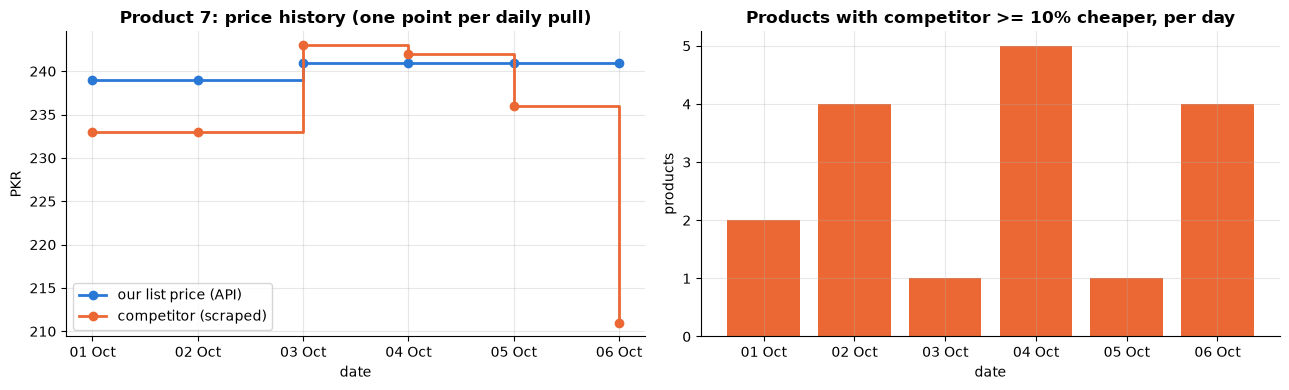

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pid = int(alerts["product_id"].iloc[0]) if len(alerts) else 0
one = wide[wide["product_id"] == pid]
import matplotlib.dates as mdates
axes[0].step(one["date"], one["own"], where="post", marker="o", label="our list price (API)")
axes[0].step(one["date"], one["competitor"], where="post", marker="o", label="competitor (scraped)")
axes[0].set(title=f"Product {pid}: price history (one point per daily pull)", ylabel="PKR", xlabel="date")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); axes[0].legend()
axes[1].bar(daily.index.strftime("%d %b"), daily["n_alerts"], color=PALETTE[1])
axes[1].set(title="Products with competitor >= 10% cheaper, per day", ylabel="products", xlabel="date")
plt.tight_layout(); plt.show()
con.close()

**What just happened?** Six simulated days produced a clean, typed history table with one row per product, day and source. The accidental re-run of the last day changed nothing, thanks to the composite primary key and the upsert. Every request is in the provenance log. The alert list (products where the competitor is at least 10% cheaper on the latest day) is exactly what a pricing team would get by email each morning. In production this script would be scheduled (cron, Airflow, Dagster), would read the token from a secrets store, and would write to a real database or Parquet files in a data lake.

> 🔎 **Why this design is robust:** retries and backoff handle a flaky API; ETags/watermarks avoid wasted downloads; robots.txt and crawl delay keep the scraping polite; regex cleaning is tested with asserts; upserts make re-runs safe; provenance makes every number traceable.

---
## 10. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same skills feed LLM training data, RAG ingestion and AI agents that call APIs.

- **LLM pre-training data** starts as web crawls (e.g. Common Crawl). Dataset builders respect robots.txt, filter by licence, strip HTML to text, deduplicate with hashes (exactly as in Section 8, plus near-duplicate methods such as MinHash), and document provenance. Several AI crawlers publish their user-agent strings so sites can opt out in robots.txt.
- **RAG systems** ([02_rag](../08_LLM/02_rag/)) ingest documents incrementally: watermarks and content hashes decide which chunks to re-embed, so you do not pay to embed unchanged pages again.
- **Tool-using LLM agents** call REST APIs exactly like our client: they need auth headers, pagination, retries with backoff and respect for 429s.
- **Feature stores and ML pipelines** ([SQL for ML features](../13_Databases/01_sql/02_industry_sql_for_ml_feature_extraction.ipynb), [data engineering](../13_Databases/06_data_engineering/01_data_engineering.ipynb)) are built on idempotent, incremental loads in Parquet/columnar formats.
- **Data governance for AI:** provenance logs and licences feed **dataset cards** and model documentation required by many organisations and by regulations such as the EU AI Act.

## Recap

- Prefer official, structured sources; check **licence, ToS, robots.txt and privacy law** before collecting.
- CSV needs explicit `encoding`, `sep`, `decimal`, `dtype` and date `format`; use a real parser for quoted fields.
- `pd.json_normalize` flattens nested JSON (`record_path` + `meta` for nested lists); JSON Lines is append-friendly.
- **Parquet** (columnar, typed, compressed) is the default for analytics; CSV for humans; Feather for fast temporary interchange.
- A robust API client uses a `Session`, auth headers, pagination, **exponential backoff with jitter**, `Retry-After` for **429**, and caching with **ETag/304**. Never retry 4xx errors (except 429).
- Scrape with stable **CSS selectors**, handle missing elements, use `pd.read_html` for tables, and crawl politely.
- Normalise Unicode before regex; store times in **UTC**, use IANA zones, and resolve DST explicitly.
- **Watermark + upsert** = incremental and idempotent loads; **provenance** (source, UTC time, SHA-256, raw file, code version) makes data traceable.

## Practice problems

**1. (Easy, coding)** Read this CSV correctly so that `price` is a float and the leading zeros of `sku` and `zip` survive: `"sku;price;zip\n007;1.050,75;01234\n042;12,00;99999\n"`.

<details><summary>Show solution</summary>

```python
import io, pandas as pd
raw = "sku;price;zip\n007;1.050,75;01234\n042;12,00;99999\n"
df = pd.read_csv(io.StringIO(raw), sep=";", decimal=",", thousands=".", dtype={"sku": str, "zip": str})
print(df)
```
`sep=";"`, `decimal=","` and `thousands="."` handle the European number style; `dtype=str` keeps identifiers as text.

</details>

**2. (Easy, conceptual)** An API returns 400, 401, 404, 429, 500 and 503 to different requests. Which ones should your client retry automatically, and how?

<details><summary>Show solution</summary>

Retry **429** (after `Retry-After` if given, otherwise backoff) and **500/503** (exponential backoff with jitter and a retry cap; 502/504 and timeouts too). Do **not** retry 400 (bad request), 401 (bad credentials) or 404 (missing resource): the same request will fail again, so fix the request or credentials instead. Also only auto-retry **idempotent** requests (GET, PUT, DELETE); retrying a POST can create duplicates unless the API supports idempotency keys.

</details>

**3. (Medium, coding)** Flatten this doubly nested JSON into one row per event, keeping the user and the session id: `{"user": "u1", "sessions": [{"id": "s1", "events": [{"type": "view", "ms": 120}, {"type": "click", "ms": 30}]}, {"id": "s2", "events": [{"type": "view", "ms": 300}]}]}`.

<details><summary>Show solution</summary>

```python
import pandas as pd
data = {"user": "u1", "sessions": [
    {"id": "s1", "events": [{"type": "view", "ms": 120}, {"type": "click", "ms": 30}]},
    {"id": "s2", "events": [{"type": "view", "ms": 300}]}]}
events = pd.json_normalize(data, record_path=["sessions", "events"], meta=["user", ["sessions", "id"]])
print(events)
```
`record_path` can be a list that walks down several levels; `meta` paths are lists of keys.

</details>

**4. (Medium, coding)** Write `backoff_schedule(max_retries, base=0.5, cap=8.0, seed=0)` that returns the wait times of "full jitter" backoff: for attempt `k`, a uniform random wait between 0 and `min(cap, base * 2**k)`. Why is jitter useful?

<details><summary>Show solution</summary>

```python
import random

def backoff_schedule(max_retries, base=0.5, cap=8.0, seed=0):
    """'Full jitter' backoff (AWS style): wait = random(0, min(cap, base * 2**k))."""
    rnd = random.Random(seed)
    return [rnd.uniform(0, min(cap, base * 2 ** k)) for k in range(max_retries)]

print([round(w, 2) for w in backoff_schedule(6)])
```
Without jitter, thousands of clients that failed at the same moment (e.g. after an outage) retry at the same moments too and knock the server over again ("thundering herd"). Random waits spread the retries out.

</details>

**5. (Medium, coding)** Write a regex-based `find_dates(text)` that finds day-first dates written as `dd/mm/yyyy`, `dd.mm.yyyy` or `dd-mm-yyyy`, ignores impossible ones (month > 12 or day > 31) and returns ISO strings. Test: `"Sale from 3/11/2026 to 15.11.2026; invalid 40/13/2026; renewal 01-02-2027."` → `['2026-11-03', '2026-11-15', '2027-02-01']`.

<details><summary>Show solution</summary>

```python
import re
DATE_RE = re.compile(r"\b(\d{1,2})[./-](\d{1,2})[./-](\d{4})\b")

def find_dates(text):
    """Return ISO dates (day-first input) for every dd/mm/yyyy, dd.mm.yyyy or dd-mm-yyyy in text."""
    out = []
    for d, m, y in DATE_RE.findall(text):
        if 1 <= int(m) <= 12 and 1 <= int(d) <= 31:
            out.append(f"{y}-{int(m):02d}-{int(d):02d}")
    return out

print(find_dates("Sale from 3/11/2026 to 15.11.2026; invalid 40/13/2026; renewal 01-02-2027."))
```
For full validation (e.g. 31 February) parse each match with `datetime.strptime` inside `try/except`.

</details>

**6. (Medium, coding)** Create a SQLite table `readings(sensor, ts, value)` and a `load(con, rows)` function that is **idempotent**: loading the same batch twice must not create duplicates, and a later corrected value for the same `(sensor, ts)` must replace the old one.

<details><summary>Show solution</summary>

```python
import sqlite3

def load(con, rows):
    con.executemany("""INSERT INTO readings VALUES (?, ?, ?)
                       ON CONFLICT(sensor, ts) DO UPDATE SET value = excluded.value""", rows)
    con.commit()

con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE readings (sensor TEXT, ts TEXT, value REAL, PRIMARY KEY (sensor, ts))")
batch = [("s1", "2026-10-27T10:00Z", 21.5), ("s1", "2026-10-27T11:00Z", 22.0), ("s2", "2026-10-27T10:00Z", 19.0)]
load(con, batch); load(con, batch)                                   # retry: same batch twice
load(con, [("s1", "2026-10-27T11:00Z", 22.4)])                       # late correction
print(con.execute("SELECT * FROM readings ORDER BY sensor, ts").fetchall())
```
The composite primary key `(sensor, ts)` plus `ON CONFLICT ... DO UPDATE` makes the load an upsert.

</details>

**7. (Medium, coding)** Scrape this HTML into a list of dicts with `title`, `city`, `pay_pkr` (int or `None` if missing) and `featured` (bool): three `div.job` cards, one without a `.pay` span, one with class `featured`.

<details><summary>Show solution</summary>

```python
from bs4 import BeautifulSoup
html = """<div class="job"><h2> Data Engineer </h2><span class="loc">Lahore</span><span class="pay">PKR 350,000</span></div>
<div class="job"><h2>ML Engineer</h2><span class="loc">Remote</span></div>
<div class="job featured"><h2>Analyst</h2><span class="loc">Karachi</span><span class="pay">Rs. 180,000</span></div>"""
soup = BeautifulSoup(html, "html.parser")
jobs = []
for job in soup.select("div.job"):
    pay = job.select_one(".pay")
    jobs.append({"title": job.h2.get_text(strip=True), "city": job.select_one(".loc").get_text(strip=True),
                 "pay_pkr": int(pay.get_text().split()[-1].replace(",", "")) if pay else None,
                 "featured": "featured" in job.get("class", [])})
print(jobs)
```

</details>

**8. (Hard, design)** Your nightly job pulls orders from a REST API with `updated_since`. One night it crashes after writing half of the pages. Describe how to make the next run produce a correct table without duplicates or gaps.

<details><summary>Show solution</summary>

1. Keep the watermark in the target database and advance it **only after** all pages were written and committed (ideally in the same transaction as the data).
2. Load with **upserts on the primary key** (order id), so pages that were already written are simply overwritten on the retry: the job is idempotent.
3. Query with `updated_since >= watermark - small overlap` (e.g. a few minutes) to cover clock skew and late commits on the source; the upsert removes the duplicates the overlap creates.
4. Stage raw pages first (content-addressed, with provenance), so you can rebuild without calling the API again.
5. Prefer **cursor-based** pagination if the API offers it, because page-number pagination can skip or repeat rows when data changes during the crawl.

</details>

## Further reading

- Wes McKinney, *Python for Data Analysis*, 3rd ed. (2022), Ch. 6 "Data Loading, Storage, and File Formats" (free online at wesmckinney.com/book).
- Ryan Mitchell, *Web Scraping with Python*, 3rd ed. (O'Reilly, 2024): scraping, crawling and ethics.
- Martin Kleppmann, *Designing Data-Intensive Applications* (2017), Ch. 4 (encoding formats) and Ch. 11 (stream processing, idempotence).
- Free: the [requests](https://requests.readthedocs.io/) and [Beautiful Soup](https://www.crummy.com/software/BeautifulSoup/bs4/doc/) documentation; RFC 9110 (HTTP semantics: status codes, `Retry-After`, ETags) and RFC 9309 (the Robots Exclusion Protocol).

## Next notebook

➡️ [13_statistical_modeling_and_inference.ipynb](13_statistical_modeling_and_inference.ipynb): now that you can collect data, learn to fit models whose **coefficients and uncertainty** you can trust.

In [27]:
shutil.rmtree(WORK, ignore_errors=True)        # remove every file this notebook created
print("Temporary folder removed:", not os.path.exists(WORK))

Temporary folder removed: True
